In [ ]:
# DONT RUN ALL.

import duckdb
import pandas as pd
import numpy as np
import csv

import matplotlib.pyplot as plt # install in POWERSHELL using "python -m pip install matplotlib"
import matplotlib.ticker as ticker
import seaborn as sns

import geopandas as gpd

%matplotlib inline

plt.style.use('themes/rose-pine.mplstyle')

con = duckdb.connect("main.duckdb")

In [54]:
# Only run at the end to save.
con.close()

In [3]:
# Set up, you only need to follow the instructions and run the first time!
# 1. Download the dataset from the census FTP (https://www2.census.gov/programs-surveys/acs/data/pums/2022/5-Year/csv_pus.zip) or try https://www2.census.gov/programs-surveys/acs/data/pums/2022/5-Year/ and navigate to csv_pus.zip
# 2. Unzip the file (may take ~10 minutes for slow computers). Make sure the folder is named "data" and the files follow the pattern "psam_pusa.csv", "psam_pusb.csv"...
# 3 Place the unzipped folder into the directory
# 4 Run this cell, which make take around 30 minutes or up to an hour on slower computers. Try to keep the computer on and just watch netflix or something on the side :)

  # Not working? You probably don't have python or duckdb installed. Use powershell (or bash if you really want) to verify that python is installed on your machine and then pip install duckdb and pandas. 
  # Ask Noam about it or use this link to try and solve it yourself (https://opentechschool.github.io/python-beginners/en/getting_started.html#what-is-python-exactly)

# Combine all the tables into table called "main" (takes ~30mins)
con.sql("""
  CREATE OR REPLACE TABLE main AS
    SELECT * FROM read_csv('data/psam_pusa.csv')
    UNION
    SELECT * FROM read_csv('data/psam_pusb.csv')
    UNION  
    SELECT * FROM read_csv('data/psam_pusc.csv')
    UNION  
    SELECT * FROM read_csv('data/psam_pusd.csv')
""")

In [ ]:
# Function for comparing table sizes and storing it in memory. Useful for seeing if your filter reduced the table to a reasonable size. 
entry_memory = {}

def compare_tables(table1, table2):
    res = con.execute(f"""
    SELECT 
        (SELECT COUNT(*) FROM "{table1}") as count1, 
        (SELECT COUNT(*) FROM "{table2}") as count2
    """).fetchone()
    c1, c2 = res[0], res[1]
    
    entry_memory[table1], entry_memory[table2] = c1, c2
    print(f"{table1}: {c1:,} | {table2}: {c2:,} | Diff: {(c2 - c1):,} ({'more' if c2 - c1 >= 0 else 'less'})")

In [2]:
# Get the data dictonary setup so you can easily translate SQL output
with open('PUMS_Data_Dictionary_2018-2022.csv', newline='') as csvfile:
    reader = csv.reader(csvfile, delimiter=",")
    output = list(reader)

# Create data_dict as a resource, then step through the document
data_dict = {}
for row in output:
    # column 1 is always NAME or VAL
    if row[0] == "NAME": 
        # IF NAME, then the second column is the name of the var, the third is the type, and the fifth is a description
        data_dict[row[1]] = {"Desc": row[4], "type": row[2],  "values": {}}
    if row[0] == "VAL":
        # IF VALUE check for type (EITHER N: Numeric, C: Character)
        if row[2] == "N": # if Numeric
            try: 
                value = int(row[5])
            except (ValueError, TypeError):
                value = str(row[5])
            if row[4] == row[5]: # if the min and the max are the same (e.g. range 1 to 1)
                data_dict[row[1]]["values"][value] = row[6]
            # Don't collect data dictionary for anything that has a range that isn't the same. An integer doesn't need a translation.

        else: # if Character
            value = str(row[5])
            data_dict[row[1]]["values"][value] = row[6]


# Function to use in order to translate dataframes or certain columns using the data-dict. (NOT FULLY TESTED!!!)
def translate(target_df, target_column = "*", translate_dict = data_dict):
    return_df = target_df.copy() # copy to avoid breaking anything
    if target_column == "*": # ALL
        xtarget = return_df
    elif isinstance(target_column, str): # string, single column, needs to be put into a list
        target_column = [target_column]
        xtarget = return_df[target_column]
    else: # handle lists
        xtarget = return_df[target_column]

    # loop through target and translate
    for series_name, series in xtarget.items():
        if series_name in translate_dict.keys():
            if translate_dict[series_name]["type"] == "C":
                return_df = return_df.astype({series_name: "str"})            
            
            return_df[series_name] = return_df[series_name].replace(translate_dict[series_name]["values"])
    
    return return_df

# Usage Guide:
    # df: plug in your whole dataframe. NO CHANGES WILL BE MADE TO THIS DATAFRAME.
    # target_column (default = ALL [*]): takes list of column names, single column name, or * (for all) and uses as target for transformation
    # translate_dict (default = data_dict): replacement translation, only for advanced purposes, defaults will work for all required work
    # Returns updated dataframe. 

##### REGION CODE ("REGION")

# 1 Northeast
# 2 Midwest
# 3 South
# 4 West
# 9 Puerto Rico

##### DIVISION CODE ("DIVISION")
# 0 Puerto Rico                              # 1 New England (Northeast region)
# 2 Middle Atlantic (Northeast region)       # 3 East North Central (Midwest region)
# 4 West North Central (Midwest region)      # 5 South Atlantic (South region)
# 6 East South Central (South region)        # 7 West South Central (South Region)
# 8 Mountain (West region)                   # 9 Pacific (West region)


##### STATE CODE ("ST")
# 01 Alabama/AL                 # 21 Kentucky/KY            # 38 North Dakota/ND
# 02 Alaska/AK                  # 22 Louisiana/LA           # 39 Ohio/OH
# 04 Arizona/AZ                 # 23 Maine/ME               # 40 Oklahoma/OK
# 05 Arkansas/AR                # 24 Maryland/MD            # 41 Oregon/OR
# 06 California/CA              # 25 Massachusetts/MA       # 42 Pennsylvania/PA
# 08 Colorado/CO                # 26 Michigan/MI            # 44 Rhode Island/RI
# 09 Connecticut/CT             # 27 Minnesota/MN           # 45 South Carolina/SC
# 10 Delaware/DE                # 28 Mississippi/MS         # 46 South Dakota/SD
# 11 District of Columbia/DC    # 29 Missouri/MO            # 47 Tennessee/TN
# 12 Florida/FL                 # 30 Montana/MT             # 48 Texas/TX
# 13 Georgia/GA                 # 31 Nebraska/NE            # 49 Utah/UT
# 15 Hawaii/HI                  # 32 Nevada/NV              # 50 Vermont/VT
# 16 Idaho/ID                   # 33 New Hampshire/NH       # 51 Virginia/VA
# 17 Illinois/IL                # 34 New Jersey/NJ          # 53 Washington/WA
# 18 Indiana/IN                 # 35 New Mexico/NM          # 54 West Virginia/WV
# 19 Iowa/IA                    # 36 New York/NY            # 55 Wisconsin/WI
# 20 Kansas/KS                  # 37 North Carolina/NC      # 56 Wyoming/WY
#                                                           # 72 Puerto Rico/PR

# Map view of codes: https://www2.census.gov/geo/pdfs/maps-data/maps/reference/us_regdiv.pdf

In [3]:
income_bin = 1000

,WithDisability,WithoutDisability
disability_type,,
DEYE,1138249.0,10173366.0
DEAR,1158699.0,10152916.0
DDRS,1861606.0,9450009.0
DREM,3281769.0,8029846.0
DOUT,3506215.0,7805400.0
DPHY,3683106.0,7628509.0


Text(0.5, 1.0, "Person's Who Collect Government Assistance Income by Disability & Disability Type")

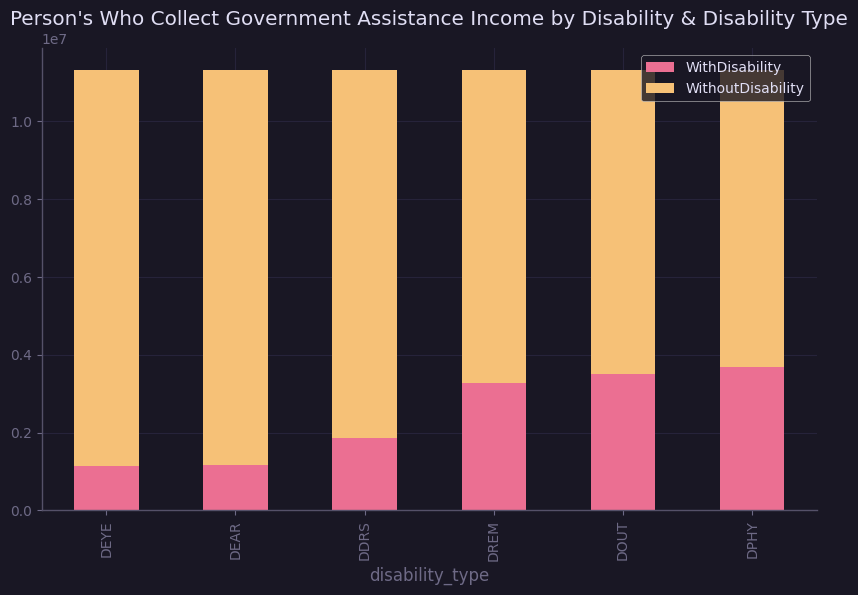

In [ ]:
q1 = con.sql(f"""
PIVOT(
SELECT 
	SUM(PWGTP) AS 'PEOPLE',
	disability_type,
	CASE WHEN disability_value = 1 THEN 'WithDisability' ELSE 'WithoutDisability' END AS 'disability_value'
FROM (
    UNPIVOT main 
    ON DEAR, DEYE, DDRS, DOUT, DREM, DPHY
    INTO 
        NAME disability_type 
        VALUE disability_value
)
WHERE PAP > 0 OR SSIP > 0
GROUP BY disability_type, disability_value
ORDER BY PEOPLE DESC
) ON disability_value USING Sum(PEOPLE)
""").df()

# q1 = translate(q1)
q1 = q1.set_index('disability_type')
q1.sort_values(by=["WithDisability"], inplace=True)
display(q1)

ax = q1.plot(kind='bar', figsize=(10, 6), stacked=True)
plt.title("Person's Who Collect Government Assistance Income by Disability & Disability Type")

,PEOPLE,CollectedAssistanceCount,CollectedAssistancePercent
SCHL_grouped,,,
N/A,35220773.0,594242.0,0.016872
Pre-diploma grade,69483550.0,2634862.0,0.037921
High school diploma,61361036.0,3226797.0,0.052587
GED,9522651.0,790692.0,0.083033
Pre-degree college,56078037.0,2086534.0,0.037208
Associates degree,21511295.0,701223.0,0.032598
Bachelors degree,50919048.0,912766.0,0.017926
Masters degree,27001204.0,364499.0,0.013499


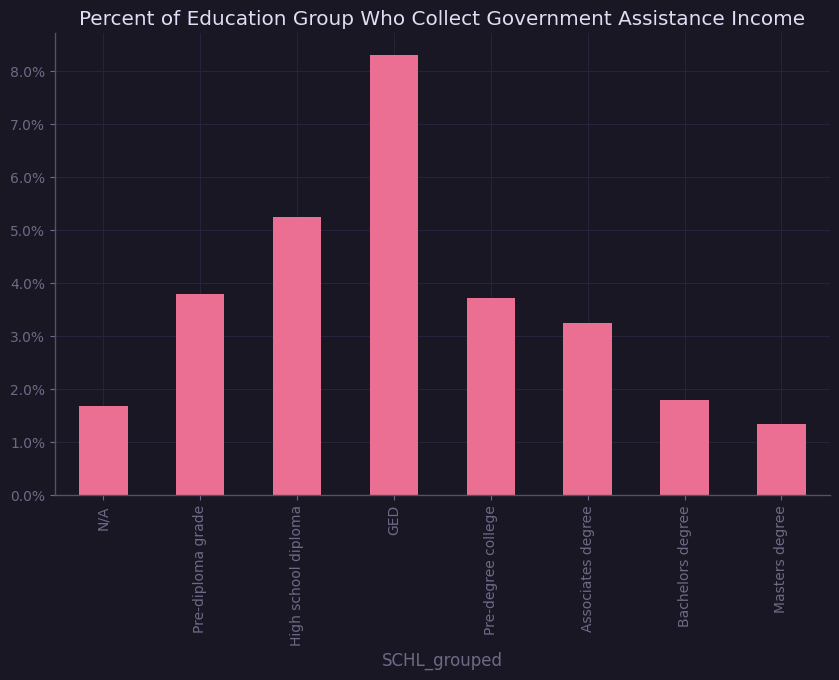

In [132]:
q2 = con.sql("""
SELECT 
	SUM(PWGTP) AS 'PEOPLE',
    SUM(CASE WHEN PAP > 0 OR SSIP > 0 THEN PWGTP ELSE 0 END) AS 'CollectedAssistanceCount',
    CASE
    	WHEN SCHL IN ('04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15') THEN 'Pre-diploma grade'
    	WHEN SCHL IN ('16') THEN 'High school diploma'
    	WHEN SCHL IN ('17') THEN 'GED'
    	WHEN SCHL IN ('18', '19') THEN 'Pre-degree college'
    	WHEN SCHL IN ('20') THEN 'Associates degree'
    	WHEN SCHL IN ('21') THEN 'Bachelors degree'
    	WHEN SCHL IN ('22', '23') THEN 'Masters degree'
    	WHEN SCHL IN ('23') THEN 'Doctorate degree'
    	ELSE 'N/A'
	END AS 'SCHL_grouped'

	--AVG(FLOOR((PAP * (ADJINC / 1000000)) / {income_bin}) * {income_bin}, 	-- Public Assistance Income
    --FLOOR((SSIP * (ADJINC / 1000000)) / {income_bin}) * {income_bin}	-- Supplementary Security Income 
FROM main
GROUP BY SCHL_grouped
""").df()

q2["SCHL_grouped"] = pd.Categorical(q2["SCHL_grouped"], categories=[
    "N/A",
	"Pre-diploma grade",
	"High school diploma",
	"GED",
	"Pre-degree college",
	"Associates degree",
	"Bachelors degree",
	"Masters degree",
	"Doctorate degree"
	], ordered=True)

q2.sort_values('SCHL_grouped', inplace=True)
q2 = q2.set_index('SCHL_grouped')

q2["CollectedAssistancePercent"] = q2["CollectedAssistanceCount"] / q2["PEOPLE"]

display(q2)

ax1 = q2["CollectedAssistancePercent"].plot(kind='bar', figsize=(10, 6), stacked=True)
plt.title("Percent of Education Group Who Collect Government Assistance Income")
ax1.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1))

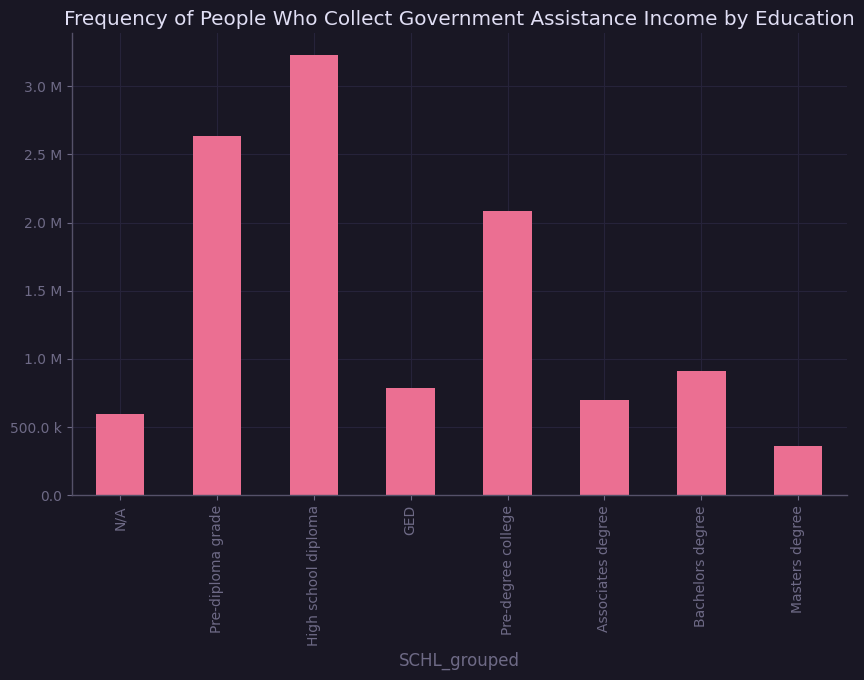

In [133]:
ax2 = q2["CollectedAssistanceCount"].plot(kind='bar', figsize=(10, 6), stacked=True)
plt.title("Frequency of People Who Collect Government Assistance Income by Education")
ax2.yaxis.set_major_formatter(ticker.EngFormatter(places=1))

,PEOPLE,CollectedAssistanceCount,CollectedAssistancePercent
ST,,,
UT,3283809.0,63644.0,0.019381
WY,577929.0,13148.0,0.022750
ND,776874.0,18748.0,0.024133
CO,5770790.0,142463.0,0.024687
NE,1958939.0,49972.0,0.025510
SD,890348.0,23768.0,0.026695
KS,2935922.0,78477.0,0.026730
TX,29243342.0,781818.0,0.026735
AZ,7172282.0,194013.0,0.027050


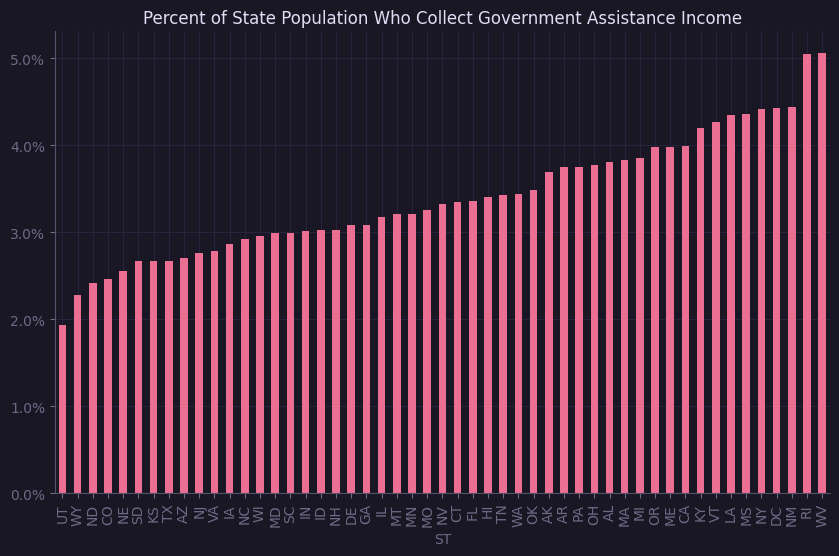

In [63]:
geotype = "ST" # ST, DIVISON, OR REGION

q3 = con.sql(f"""
SELECT 
	SUM(PWGTP) AS 'PEOPLE',
	SUM(CASE WHEN PAP > 0 OR SSIP > 0 THEN PWGTP ELSE 0 END) AS 'CollectedAssistanceCount',
	{geotype}
	--FLOOR((PAP * (ADJINC / 1000000)) / {income_bin}) * {income_bin}, 	-- Public Assistance Income
    --FLOOR((SSIP * (ADJINC / 1000000)) / {income_bin}) * {income_bin}	-- Supplementary Security Income  
FROM main
GROUP BY {geotype}
""").df()

q3 = translate(q3)

q3["CollectedAssistancePercent"] = q3["CollectedAssistanceCount"] / q3["PEOPLE"]
if geotype == "ST":
    q3["ST"] = q3['ST'].str[-2:]

q3.sort_values('CollectedAssistancePercent', inplace=True)
q3 = q3.set_index(geotype)

display(q3)


ax = q3["CollectedAssistancePercent"].plot(kind='bar', figsize=(10, 6), stacked=True)
plt.title("Percent of State Population Who Collect Government Assistance Income")
ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1))

In [ ]:
states = gpd.read_file("./data/cb_2018_us_state_500k/")
states = states[~states.STATEFP.isin(["72", "69", "60", "66", "78"])]
states = states.to_crs("ESRI:102003")

# Adjust Alaska & Hawaii
def translate_geometries(df, x, y, scale, rotate):
    df.loc[:, "geometry"] = df.geometry.translate(yoff=y, xoff=x)
    center = df.dissolve().centroid.iloc[0]
    df.loc[:, "geometry"] = df.geometry.scale(xfact=scale, yfact=scale, origin=center)
    df.loc[:, "geometry"] = df.geometry.rotate(rotate, origin=center)
    return df

def adjust_maps(df):
    df_main_land = df[~df.STATEFP.isin(["02", "15"])]
    df_alaska = df[df.STATEFP == "02"]
    df_hawaii = df[df.STATEFP == "15"]

    df_alaska = translate_geometries(df_alaska, 1300000, -4900000, 0.5, 32)
    df_hawaii = translate_geometries(df_hawaii, 5400000, -1500000, 1, 24)

    return pd.concat([df_main_land, df_alaska, df_hawaii])

states = adjust_maps(states)

states = states.set_index("STUSPS")


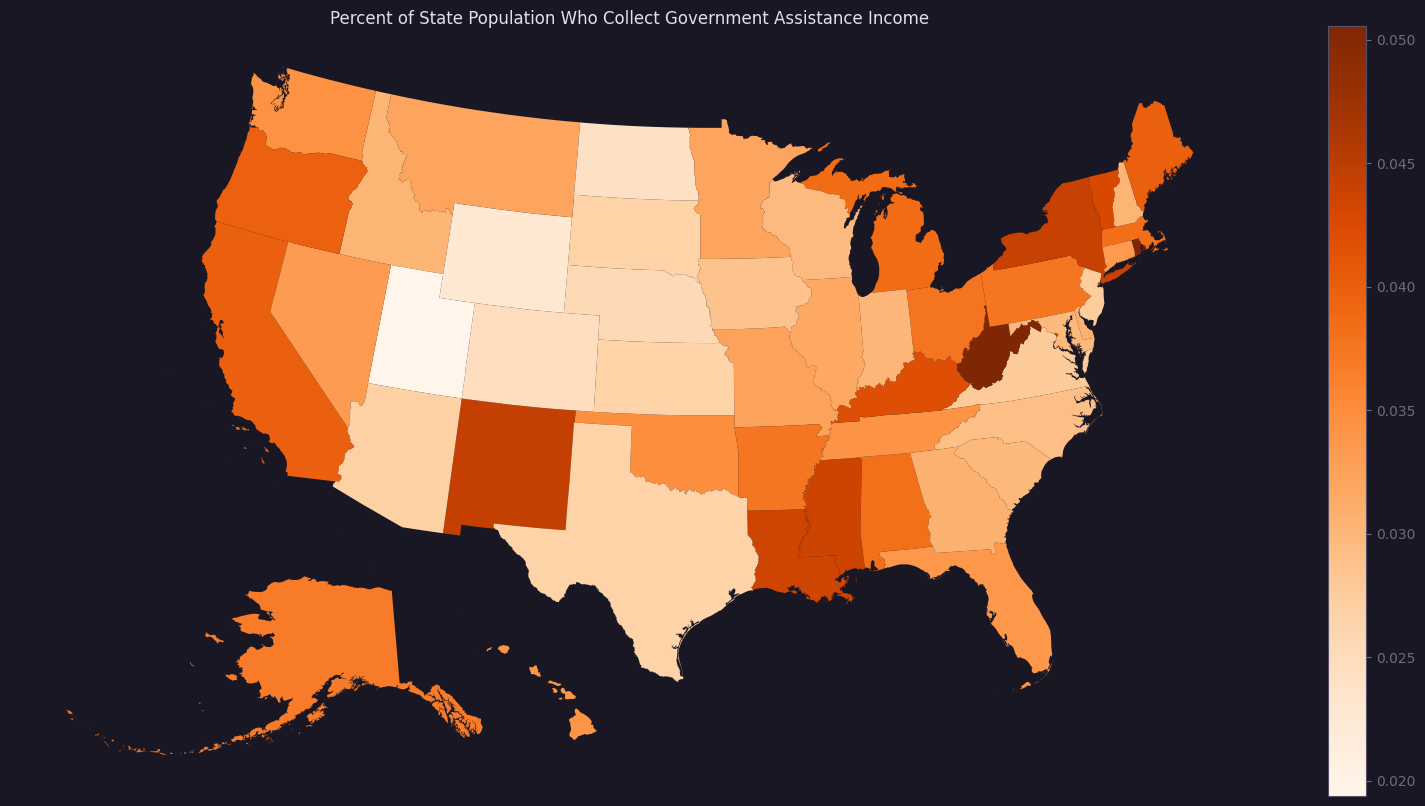

In [65]:
plt.style.use('themes/rose-pine.mplstyle')
q3_combined = states.join(q3)

ax = q3_combined.plot(column="CollectedAssistancePercent", figsize=(20, 10), legend=True, cmap='Oranges')
plt.title("Percent of State Population Who Collect Government Assistance Income")
plt.axis("off")
plt.show()